# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn (including DecisionTreeClassifier, RandomForestClassifier and GradingBoostingClassifier)
- Matplotlib


In [108]:
# Add code here 🔧
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

(29504, 15)
        customer_id      answered         income           age           job  \
count  29504.000000  29504.000000   29504.000000  29504.000000  29504.000000   
mean   14850.475563      0.546638   33766.893303     34.773454      1.915401   
std     8517.254310      0.497829   29379.202710     11.369865      0.658183   
min       99.000000      0.000000  -65600.000000     19.000000      0.000000   
25%     7474.750000      0.000000   13550.000000     26.000000      2.000000   
50%    14850.500000      1.000000   23310.000000     32.000000      2.000000   
75%    22226.250000      1.000000   41690.000000     40.000000      2.000000   
max    29602.000000      1.000000  159450.000000    132.000000      3.000000   

       num_dependents          rent       own_res       new_car      chk_acct  \
count    29504.000000  29504.000000  29504.000000  29502.000000  29504.000000   
mean         1.140998      0.210412      0.681128      0.240797      1.468547   
std          0.348025   

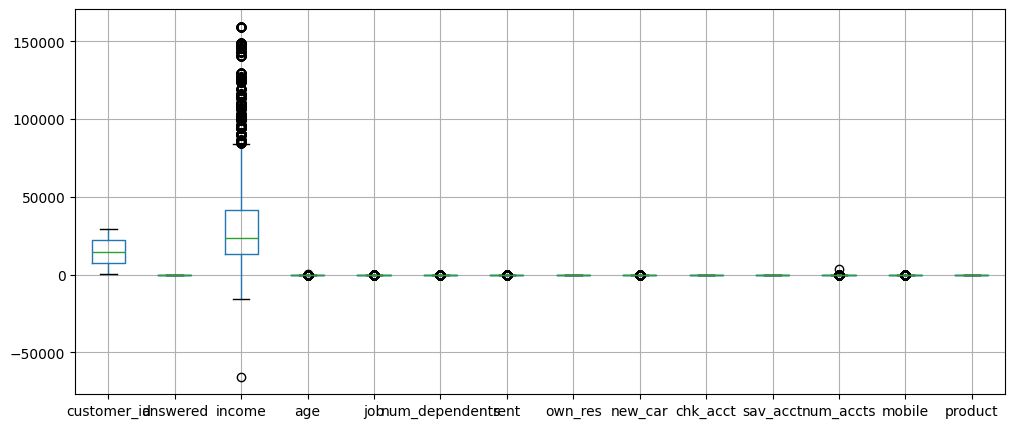

In [109]:
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv"
df = pd.read_csv(url)

print(df.shape)
print(df.describe())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

df.boxplot(figsize=(12, 5))
plt.show()

### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. Income seems very unusual. First off we have multiple instances of negative income. We also have a lot of outliers towards the top that are skewing income towards the right.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [110]:
# Add code here 🔧
df_clean = df.drop_duplicates()
df_clean = df_clean[df_clean["income"] >= 0]
df_clean = df_clean[df_clean["num_accts"] < 100]
df_clean = df_clean.dropna()
df_clean = df_clean.drop(columns=["customer_id", "product"])

print(df_clean.shape)
print(df_clean.isnull().sum().sum(), df_clean.duplicated().sum())

(29496, 13)
0 29032


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed 3 duplicate rows, the record with negative income, and extreme number of account values. I kept high incomes because they could be real. I also deleted the two rows of missing new car because 2 rows out of 29000 is negligible

2.6 I removed customer id because it is an identifier with no predictive value. I removed product because it is only know after the call and would leak the answer into the model.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [111]:
# Add code here 🔧
df_clean["answered"] = df_clean["answered"].astype(bool)

int_cols = ["income", "age", "job", "num_dependents", "rent", "own_res",
            "new_car", "chk_acct", "sav_acct", "num_accts", "mobile"]
df_clean[int_cols] = df_clean[int_cols].astype(int)

print(df_clean.dtypes)

answered            bool
income             int64
female            object
age                int64
job                int64
num_dependents     int64
rent               int64
own_res            int64
new_car            int64
chk_acct           int64
sav_acct           int64
num_accts          int64
mobile             int64
dtype: object


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [112]:
# Add code here 🔧
cat_cols = ["job", "chk_acct", "sav_acct"]
df_clean[cat_cols] = df_clean[cat_cols].astype("category")

print(df_clean.dtypes)

answered              bool
income               int64
female              object
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



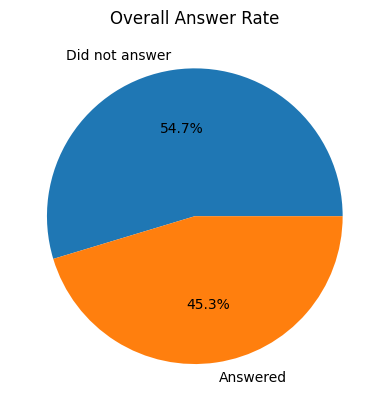

In [113]:
# Chart 3.1 🔧
df_clean["answered"].value_counts().plot(kind="pie", autopct="%1.1f%%", labels=["Did not answer", "Answered"])
plt.title("Overall Answer Rate")
plt.ylabel("")
plt.show()

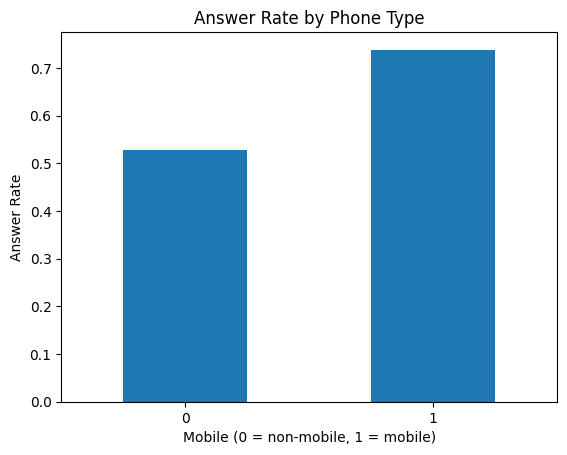

In [114]:
# Chart 3.2 🔧
df_clean.groupby("mobile")["answered"].mean().plot(kind="bar")
plt.title("Answer Rate by Phone Type")
plt.xlabel("Mobile (0 = non-mobile, 1 = mobile)")
plt.ylabel("Answer Rate")
plt.xticks(rotation=0)
plt.show()

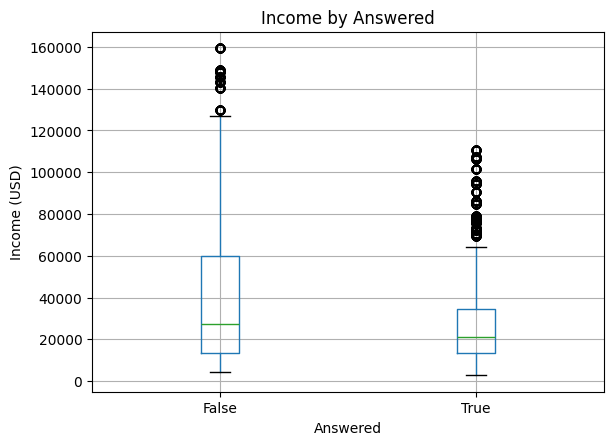

In [115]:
# Chart 3.3 🔧
df_clean.boxplot(column="income", by="answered")
plt.title("Income by Answered")
plt.suptitle("")
plt.xlabel("Answered")
plt.ylabel("Income (USD)")
plt.show()

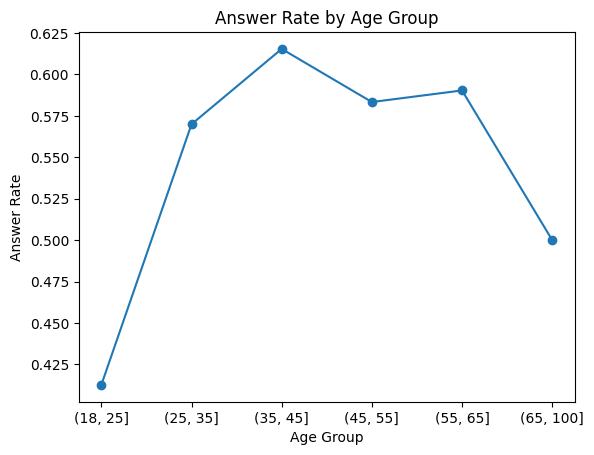

In [116]:
# Chart 3.4 🔧
age_groups = pd.cut(df_clean["age"], bins=[18, 25, 35, 45, 55, 65, 100])
df_clean.groupby(age_groups, observed=True)["answered"].mean().plot(kind="line", marker="o")
plt.title("Answer Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Answer Rate")
plt.show()

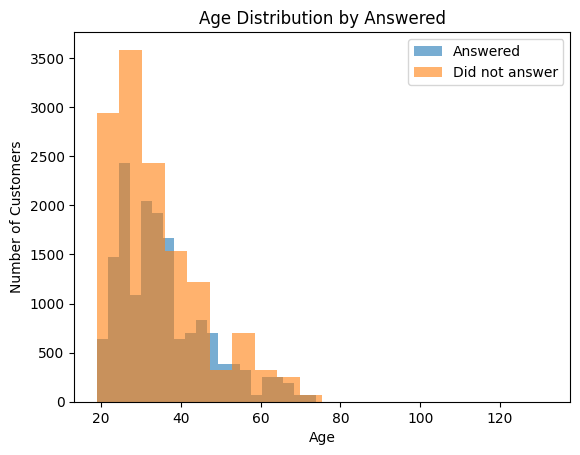

In [117]:
# Chart 3.5 🔧
plt.hist(df_clean[df_clean["answered"]]["age"], bins=20, alpha=0.6, label="Answered")
plt.hist(df_clean[~df_clean["answered"]]["age"], bins=20, alpha=0.6, label="Did not answer")
plt.title("Age Distribution by Answered")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Mobile has the strongest relationship. 73% of mobile phone customers answered versus 53% of nonmobile customers. Income also showed a strong relationship, customer who answered had a lower median income and small variance.

3.7. The age histograms for answered and njot answered overlap a lot, showing that age isn't a good separator. However I wouldn't remove it because it only shows counts, and young customers are just more common overall.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [118]:
# Add code here 🔧
p_answer = df_clean["answered"].mean()
print("P(answer):", round(p_answer, 4))
print("P(no answer):", round(1 - p_answer, 4))

P(answer): 0.5467
P(no answer): 0.4533


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [119]:
# Add code here 🔧
from sklearn.model_selection import train_test_split

X = pd.get_dummies(df_clean.drop(columns=["answered"]), columns=["job", "chk_acct", "sav_acct"])
y = df_clean["answered"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(20647, 22) (8849, 22)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

bool     13
int64     9
Name: count, dtype: int64
[0 1]


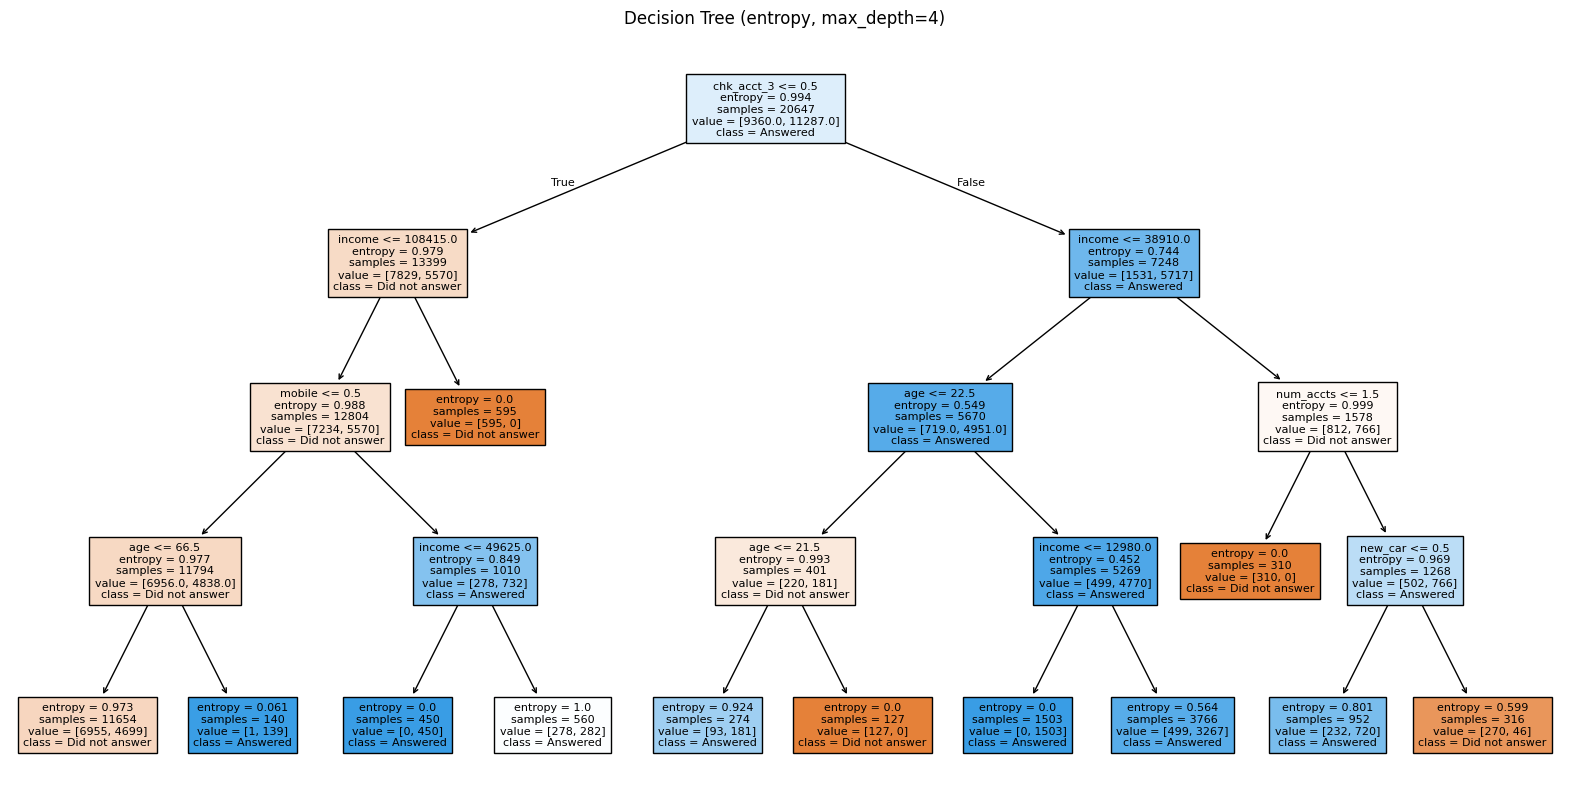

In [120]:
# Add code here 🔧
df_clean["female"] = df_clean["female"].replace({"M": "0"}).astype(int)

X = pd.get_dummies(df_clean.drop(columns=["answered"]), columns=["job", "chk_acct", "sav_acct"])
y = df_clean["answered"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(X_train.dtypes.value_counts())
print(df_clean["female"].unique())

tree = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
tree.fit(X_train, y_train)

plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=X_train.columns, class_names=["Did not answer", "Answered"], filled=True, fontsize=8)
plt.title("Decision Tree (entropy, max_depth=4)")
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [121]:
# Add code here 🔧
from sklearn.metrics import accuracy_score

y_pred = tree.predict(X_test)
print("Tree accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Baseline:", round(max(p_answer, 1 - p_answer), 4))

Tree accuracy: 0.7133
Baseline: 0.5467


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The tree's accuracy is 71% vs the baseline of 55%, which is a big improvement. The tree correctly predicts whether a customer will answer more often than guessing the majority.

2. Yes, about half of scheduled calls go unanswered, so reps sit idle unevenly. A model that identifies likely answerers 71% of the time lets AdviseInvest schedule calls more intelligently. It should cut idle rep time and increase the number of completed conversations.


## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

[[3578  434]
 [2103 2734]]


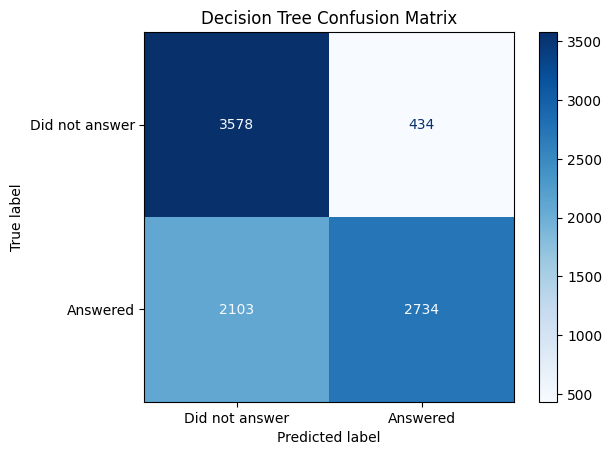

In [122]:
# Add code here 🔧
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["Did not answer", "Answered"]).plot(cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.show()

Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

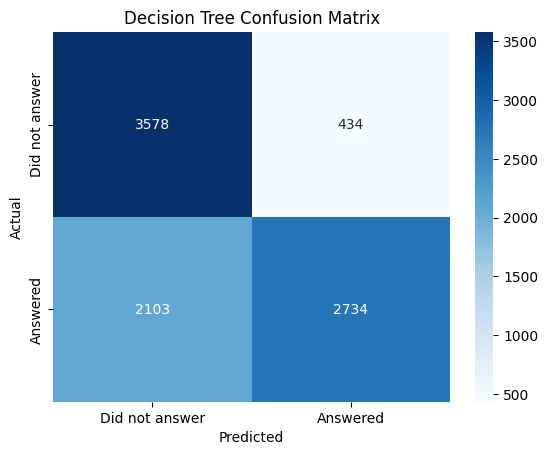

In [123]:
# Add code here 🔧
import seaborn as sns
labels = ["Did not answer", "Answered"]
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

In [124]:
# Add code here 🔧
train_acc = accuracy_score(y_train, tree.predict(X_train))
test_acc = accuracy_score(y_test, tree.predict(X_test))

print("Training accuracy:", round(train_acc, 4))
print("Testing accuracy:", round(test_acc, 4))
print("Difference:", round(train_acc - test_acc, 4))

Training accuracy: 0.7168
Testing accuracy: 0.7133
Difference: 0.0035


### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1. The model is reasonably balanced. Training accuracy and testing accuracy are roughly equal. Testing accuracy is also above baseline.
2. Not applicable, accuracies are close to equal
3. Not applicable, test accuracy is well above baseline

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [125]:
# Add code here 🔧
tn, fp, fn, tp = cm.ravel()

profit = tp * 75 - fp * 25
print("True positives:", tp)
print("False positives:", fp)
print("Profit using the model: $", profit)

True positives: 2734
False positives: 434
Profit using the model: $ 194200


## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [126]:
# Add code here 🔧
all_answered = (y_test == True).sum()      # all answerers treated as true positives
all_not_answered = (y_test == False).sum() # all non-answerers treated as false positives

profit_all = all_answered * 75 - all_not_answered * 25
print("Answered:", all_answered)
print("Did not answer:", all_not_answered)
print("Profit if everyone is called: $", profit_all)
print("Model profit minus baseline: $", profit - profit_all)

Answered: 4837
Did not answer: 4012
Profit if everyone is called: $ 262475
Model profit minus baseline: $ -68275


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling everyone earns 262475, calling only recommendations earns 194200. The difference is 68275.

2. Yes, this gap is significant. Answered calls earn 75 and wasted calls cost 25, so skipping answerers is expensive. The tree skips 2100+ customers who would have answered, missing out on over 150000+ in profits. This outweighs the cost savings from fewer wasted calls.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [127]:
# Add code here 🔧
tree2 = DecisionTreeClassifier(criterion="entropy", max_depth=6, min_samples_leaf=50, random_state=42)
tree2.fit(X_train, y_train)

train_acc2 = accuracy_score(y_train, tree2.predict(X_train))
test_acc2 = accuracy_score(y_test, tree2.predict(X_test))

print("New training accuracy:", round(train_acc2, 4))
print("New testing accuracy:", round(test_acc2, 4))
print("Original testing accuracy:", round(test_acc, 4))

New training accuracy: 0.7566
New testing accuracy: 0.7505
Original testing accuracy: 0.7133


## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

Random forest test accuracy: 1.0
Tuned tree test accuracy: 0.7505


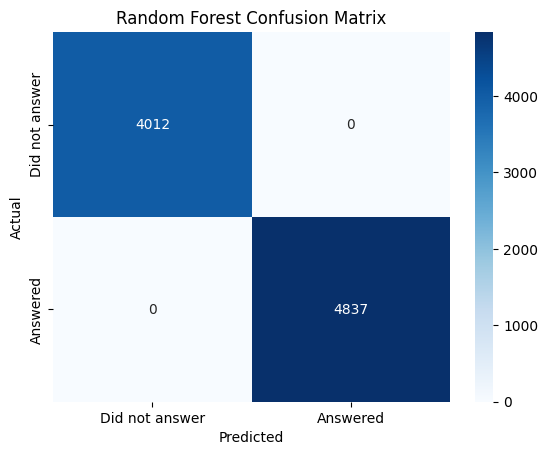

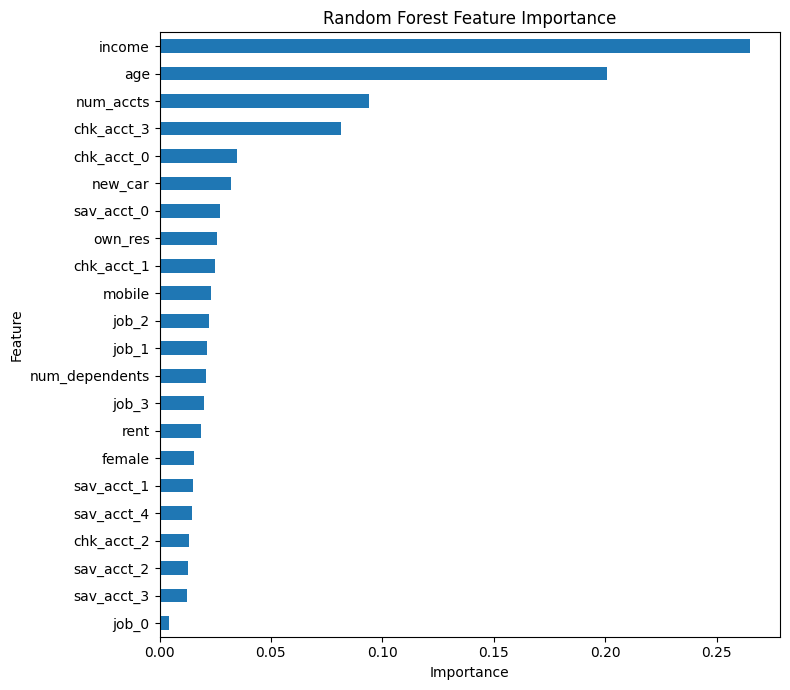

In [128]:
# Add code here 🔧
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
print("Random forest test accuracy:", round(rf_acc, 4))
print("Tuned tree test accuracy:", round(test_acc2, 4))

# Confusion matrix
rf_cm = confusion_matrix(y_test, rf_pred)
labels = ["Did not answer", "Answered"]
sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Feature importance
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
importances.plot(kind="barh", figsize=(8, 7))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1. The random forest had a suspiciously perfect score which doesn't seem like a possibility. There are probably duplicate rows or some other bad data and the model accuracy is much lower.
2. Income and age were the most important. They mostly matched the top of the decision tree because both models relied on the same core predictors.

### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

Gradient boosting test accuracy: 0.8809
Gradient boosting training accuracy: 0.8899


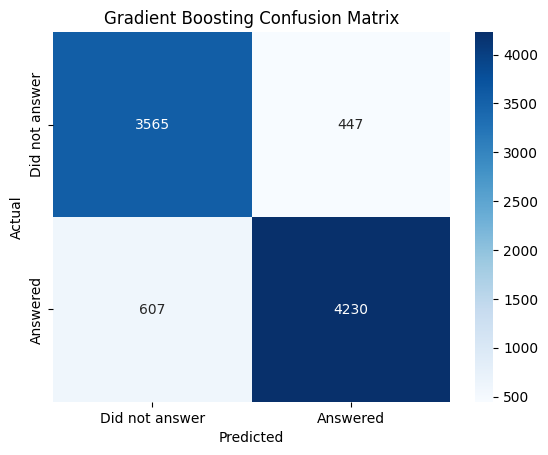

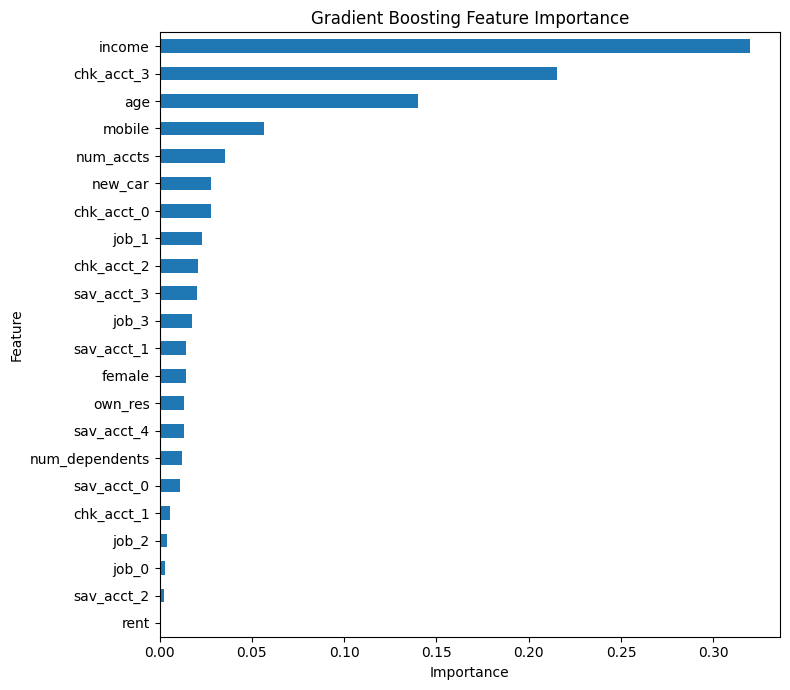

In [129]:
# Add code here 🔧
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train, y_train)

gb_pred = gb.predict(X_test)
print("Gradient boosting test accuracy:", round(accuracy_score(y_test, gb_pred), 4))
print("Gradient boosting training accuracy:", round(accuracy_score(y_train, gb.predict(X_train)), 4))

gb_cm = confusion_matrix(y_test, gb_pred)
labels = ["Did not answer", "Answered"]
sns.heatmap(gb_cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Gradient Boosting Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

gb_importances = pd.Series(gb.feature_importances_, index=X_train.columns).sort_values()
gb_importances.plot(kind="barh", figsize=(8, 7))
plt.title("Gradient Boosting Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧

1. Random forest had a perfect score and gradient boosting had an .8809. so the random forest was higher although I dont think it was real. Both numbers seem to be inflated from duplicate data or something. Both models are way above the baseline.
2. A random forest build many trees independently on random samples of the data and averages their votes. Gradient boosting builds trees one after another, and each new tree focuses on correcting the errors of the previous ones. Boosting can learn complex patterns but is prone to overfitting.


## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

In [135]:
model_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [tree_accuracy, rf_accuracy, gb_accuracy],
    'True Positives': [tree_tp, rf_tp, gb_tp],
    'False Positives': [tree_fp, rf_fp, gb_fp],
    'Estimated Profit': [tree_profit, rf_profit, gb_profit]
})

NameError: name 'tree_accuracy' is not defined

                 Model  Test Accuracy  True Positives  False Positives  \
0  Tuned Decision Tree         0.7505            2900              271   
1        Random Forest         1.0000            4837                0   
2    Gradient Boosting         0.8809            4230              447   

   Estimated Profit  
0            210725  
1            362775  
2            306075  


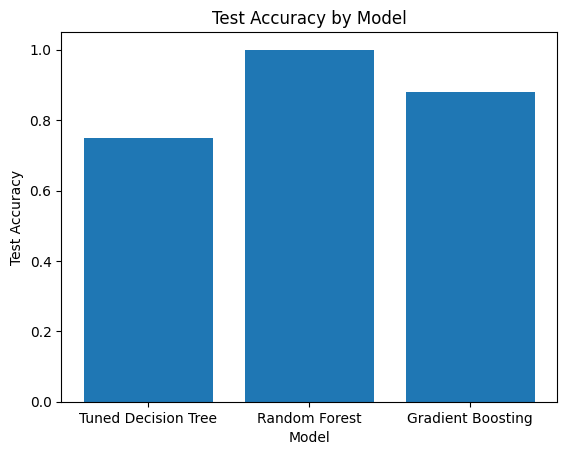

In [137]:
def evaluate(name, model):
    pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "Model": name,
        "Test Accuracy": round(accuracy_score(y_test, pred), 4),
        "True Positives": tp,
        "False Positives": fp,
        "Estimated Profit": tp * 75 - fp * 25,
    }

model_results = pd.DataFrame([
    evaluate("Tuned Decision Tree", tree2),
    evaluate("Random Forest", rf),
    evaluate("Gradient Boosting", gb),
])
print(model_results)

plt.bar(model_results["Model"], model_results["Test Accuracy"])
plt.title("Test Accuracy by Model")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1.05)
plt.show()

## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

In [138]:
# Add code here 🔧
url_new = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv"
df_new = pd.read_csv(url_new)
df_new.columns = df_new.columns.str.lower()
print(df_new.shape)
print(df_new.isnull().sum())

df_new = df_new.drop_duplicates(subset="customer_id") if "customer_id" in df_new.columns else df_new
ids = df_new["customer_id"] if "customer_id" in df_new.columns else None
df_new = df_new.drop(columns=[c for c in ["customer_id", "product", "answered"] if c in df_new.columns])

df_new["female"] = df_new["female"].replace({"M": "0"}).astype(int)
df_new = df_new.fillna(df_new.median(numeric_only=True))

int_cols = ["income", "age", "job", "num_dependents", "rent", "own_res",
            "new_car", "chk_acct", "sav_acct", "num_accts", "mobile"]
df_new[int_cols] = df_new[int_cols].astype(int)

cat_cols = ["job", "chk_acct", "sav_acct"]
df_new[cat_cols] = df_new[cat_cols].astype("category")

X_new = pd.get_dummies(df_new, columns=cat_cols)
X_new = X_new.reindex(columns=X_train.columns, fill_value=0)
print(X_new.shape, X_train.shape)

new_pred = gb.predict(X_new)
df_new["predicted_answered"] = new_pred

print(df_new["predicted_answered"].value_counts())
print("Predicted to answer:", new_pred.sum())
print("Predicted not to answer:", (~new_pred).sum())

(1000, 13)
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
customer_id       0
dtype: int64
(1000, 22) (20647, 22)
predicted_answered
True     526
False    474
Name: count, dtype: int64
Predicted to answer: 526
Predicted not to answer: 474


### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
 1. The random forest had the highest profit (362775) and the highest accuracy. The accuracy is perfect and not believable..
 2. Accuracy isn't the only goal. A simpler model may be easier to explain and maintain. A model that is slightly less accurate can also earn more profit if it makes fewer costly mistakes.
 3. The decision tree is the easiest to explain. The DoS can easily follow the splits step by step. I would recommend gradient boosting because it has the most trustworth accuracy and profit numbers.






# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 Yes, calling every customer earns 262475 dollars while the gradient boosting model earns 306075 dollars. It does this by cutting wasted calls by around 90 percent, 4000 to 450.

6.2 AdviseInvest could score each scheduled customer before the call window and prioritize those with high likeliness to answer scores. The model can help predict the surges and slow times to staff reps accordingly. The model should be retrained as data is logged and checked against results over time for constant improvements.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"